# Latent Space Learning for GPI

## Imports

In [20]:
import zarr, torch, time
import numpy as np

from src.visualization import *
from src.metrics import *

import warnings
warnings.simplefilter("ignore")

In [15]:
store = zarr.open("pusht/pusht_cchi_v7_replay.zarr", mode="r")
endpoints = store["meta/episode_ends"]
checkpoints = np.concat([[0], endpoints])
DEVICE = torch.device("cuda" if torch.cuda.is_available() else "cpu")

## AutoEncoder

In [8]:
from src.dataset import ZarrDataset
from torch.utils.data import DataLoader
from src.autoencoder import StandardAutoencoder, Encoder, Decoder
from src.autoencoder_training_utils import train_standard_ae
from torch import nn, optim
from src.embedding_utils import *

In [ ]:
dataset = ZarrDataset("pusht/pusht_cchi_v7_replay.zarr", nepisodes=200)
loader = DataLoader(dataset, batch_size=64, num_workers=0, shuffle=True)
encoder = Encoder(in_channels=3, z_dim=512, pool_output=(6,6))
decoder = Decoder(out_channels=3, z_dim=512, initial_shape=(6,6), out_shape=(96,96))

autoencoder = StandardAutoencoder(encoder, decoder).to(DEVICE)
criterion = nn.MSELoss() # Reconstruction Loss (MSE is standard)
optimizer = optim.Adam(autoencoder.parameters(), lr=1e-3)

t0 = time.time()
train_standard_ae(autoencoder, loader, criterion, optimizer, DEVICE, 500)
print("Standard Autoencoder Training Complete.")
tf = time.time()
print(f"Total Training Time: {tf - t0:.2f} seconds")
# torch.save(autoencoder.state_dict(), f"checkpoints/standard_ae.pt")

dataset = ZarrDataset("pusht/pusht_cchi_v7_replay.zarr")
loader = DataLoader(dataset, batch_size=64, num_workers=0, shuffle=False)
embeddings = embs_from_dataloader(autoencoder, loader, DEVICE)
# torch.save(embeddings, "standard_ae.pt")

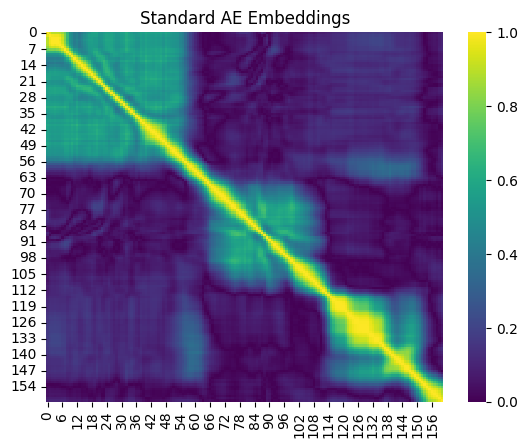

In [4]:
data_standard = torch.load('embeddings/standard_ae.pt')
data_standard = data_standard - torch.mean(data_standard, dim=0) 
_ = emb_hmap(data_standard[:161], title="Standard AE Embeddings", dist="cosine")
_, avg_dist_standard, var_dist_standard = emb_hmap(data_standard[:161], dist="l2", plot=False)

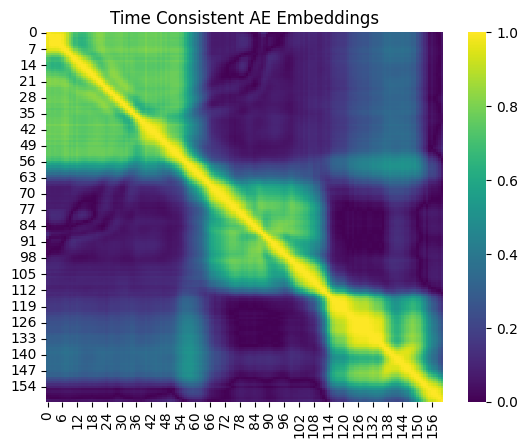

In [5]:
data_consistent = torch.load('embeddings/time_consistent_ae.pt')
data_consistent = data_consistent - torch.mean(data_consistent, dim=0) 
_ = emb_hmap(data_consistent[:161], title="Time Consistent AE Embeddings", dist="cosine")
_, avg_dist_consistent, var_dist_consistent = emb_hmap(data_consistent[:161], dist="l2", plot=False)

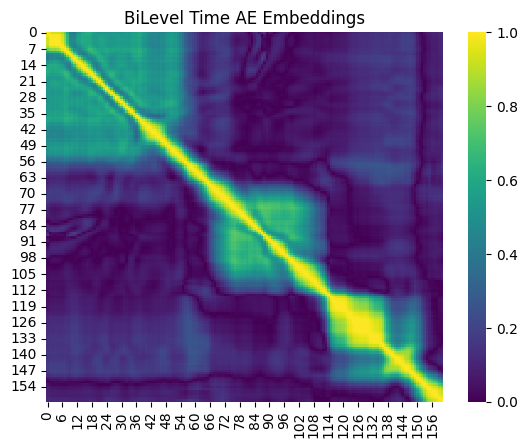

In [6]:
data_bilevel = torch.load('embeddings/bilevel_time_ae.pt')
data_bilevel = data_bilevel - torch.mean(data_bilevel, dim=0) 
_ = emb_hmap(data_bilevel[:161], title="BiLevel Time AE Embeddings", dist="cosine")
_, avg_dist_bilevel, var_dist_bilevel = emb_hmap(data_bilevel[:161], dist="l2", plot=False)

## Pretrained Vision Models

In [13]:
from src.embedding_head import DinoModel, FineTunedEmbedding, FineTunedHead
from src.fine_tuning_utils import train_loop

In [ ]:
model = DinoModel("facebook/dinov3-convnext-small-pretrain-lvd1689m")
dataloader = DataLoader(dataset, batch_size=64, shuffle=False)
t0 = time.time()
embeddings = embs_from_dataloader(model, dataloader, DEVICE)
tf = time.time()
# torch.save(embeddings, "dino_tiny_pretrained.pt")

In [ ]:
model = FineTunedEmbedding(None, FineTunedHead(input_dim=768, hidden_dim=768, output_dim=512)).to(DEVICE)

dataset = ZarrDataset("pusht/pusht_cchi_v7_replay.zarr", nepisodes=200)
model.load_precomputed_embeddings("embeddings/dino_tiny_pretrained.pt")
t0 = time.time()
train_loop(model, dataset, lambda_=5.0, temp=0.1, device=DEVICE, max_distance=None, add_steps=10, uniform=True, epochs=10, lr=1e-3)
tf = time.time()
print(f"Total Training Time: {tf - t0:.2f} seconds")
# Save the fine-tuned model
# torch.save(model.head_model.state_dict(), "arms_tuned_embedding_head.pth")

data_new = model.head_model(model.embeddings)
# torch.save(data_new, "contrastive_learning.pt")

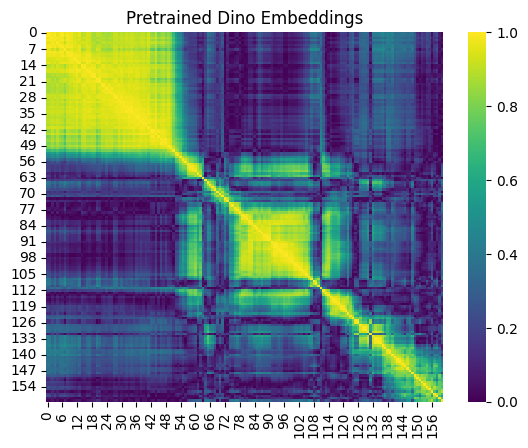

In [22]:
data_pretrained = torch.load('embeddings/dino_tiny_pretrained.pt')
data_pretrained = data_pretrained - torch.mean(data_pretrained, dim=0) 
_ = emb_hmap(data_pretrained[:161], title="Pretrained Dino Embeddings", dist="cosine")
_, avg_dist_pretrained, var_dist_pretrained = emb_hmap(data_pretrained[:161], dist="l2", plot=False)

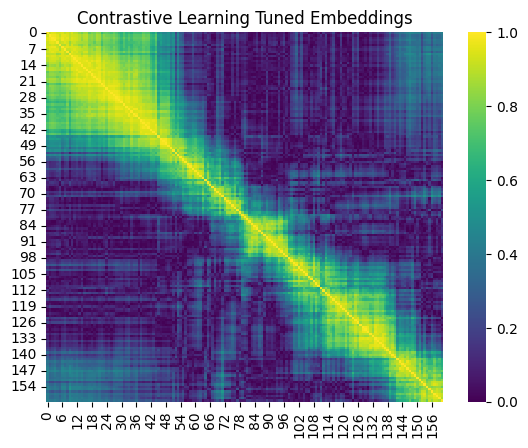

In [25]:
data_cl = torch.load('embeddings/contrastive_learning.pt', map_location=DEVICE).detach()
data_cl = data_cl - torch.mean(data_cl, dim=0) 
_ = emb_hmap(data_cl[:161], title="Contrastive Learning Tuned Embeddings", dist="cosine")
_, avg_dist_cl, var_dist_cl = emb_hmap(data_cl[:161], dist="l2", plot=False)

## Multimodal Models

In [26]:
from src.embedding_head import BLIPModel

In [ ]:
txt_prompt = "Provide an accurate position estimate for the blue dot in the image, disregarding the green t-shape, the grey t-shape and the background."
model = BLIPModel('Salesforce/instructblip-flan-t5-xl', text_prompt=txt_prompt)
dataloader = DataLoader(dataset, batch_size=64, shuffle=False)
t0 = time.time()
embeddings = embs_from_dataloader(model, dataloader, DEVICE)
tf = time.time()
# torch.save(embeddings, "prompt_tuned.pt")

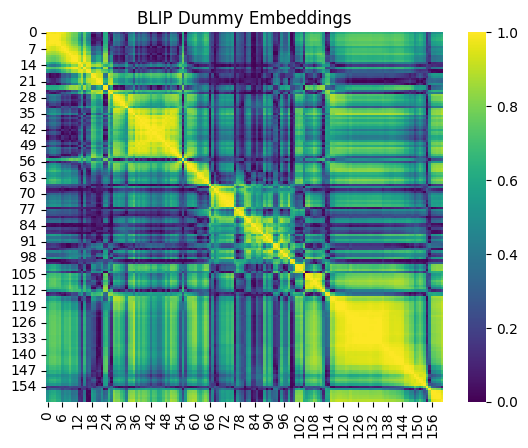

In [27]:
data_dummy = torch.load('embeddings/blip_dummy.pt', map_location=DEVICE).detach()
data_dummy = data_dummy - torch.mean(data_dummy, dim=0) 
_ = emb_hmap(data_dummy[:161], title="BLIP Dummy Embeddings", dist="cosine")
_, avg_dist_dummy, var_dist_dummy = emb_hmap(data_dummy[:161], dist="l2", plot=False)

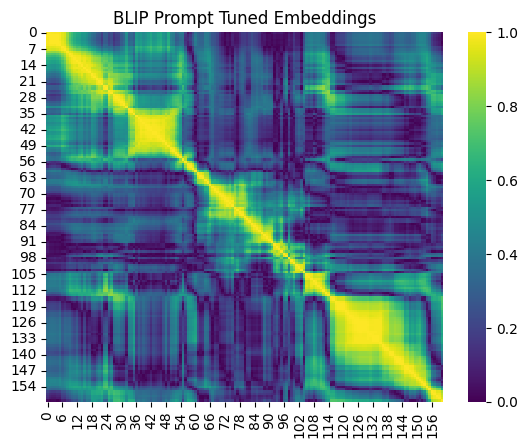

In [28]:
data_prompt = torch.load('embeddings/prompt_tuned.pt', map_location=DEVICE).detach()
data_prompt = data_prompt - torch.mean(data_prompt, dim=0) 
_ = emb_hmap(data_prompt[:161], title="BLIP Prompt Tuned Embeddings", dist="cosine")
_, avg_dist_prompt, var_dist_prompt = emb_hmap(data_prompt[:161], dist="l2", plot=False)